# DOE-050
## PPF ウィンドウ確認

- 目的: PPF ウィンドウ確認
- 対象銘柄: 9984
- 実験計画: 完全実施要因計画 (Full Factorial Design)
- 実験パラメータ
- 固定パラメータ
    - TYPE_MA_1: PPF
    - GAIN_MA_1: 0.005
    - GAIN_PREDICT_MA_1: 0.50
    - PERIOD_MA_1 (TREND_PERIOD in PPF): 80
        - 短周期移動平均線
    - PERIOD_MA_2: 2400
        - 長周期移動平均線
    - START_TRAILING: 20
        - トレーリング・ストップを開始する最大含み益
    - THRESHOLD_TRAILING: 0.90
        - トレーリング・ストップのしきい値比
    - FOLLOWING_MIN: 15
        - 順方向に設定回数以上更新されていて含み損になればロスカット
    - LOSSCUT_SIMPLE: float = -50
        - 単純ロスカット
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
    - クロス時に反対売買をしない。
- 評価指標
    - 収益と約定回数

In [38]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-050"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../../backtest/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "GAIN_MA_1",
    "GAIN_PREDICT_MA_1",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [
        pd.read_csv(file).assign(
            DATE=pd.to_datetime(Path(file).stem[:8], format="%Y%m%d")
        )
        for file in list_csv_file
    ],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Mean=("Profit", "mean"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df)
print("\nSummary Statistics")
print(df_total)
print("\n*** Past", len(list_csv_file), "days statistics ***")
print("\n△ Profit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
print("\n▼ Profit_Total Bottom 3")
print(df_total.nsmallest(3, "Profit_Total"))
print("\n\n△ Profit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
print("\n▼ Profit_Median Bottom 3")
print(df_total.nsmallest(3, "Profit_Median"))

     TYPE_MA_1  PERIOD_MA_1  GAIN_MA_1  GAIN_PREDICT_MA_1  Profit  Transactions       DATE
0          PPF           80     0.0030                0.3   -55.0           8.0 2026-09-01
1          PPF           80     0.0035                0.3     2.0           8.0 2026-09-01
2          PPF           80     0.0040                0.3     0.0           8.0 2026-09-01
3          PPF           80     0.0045                0.3    -4.0          10.0 2026-09-01
4          PPF           80     0.0050                0.3   -16.0          10.0 2026-09-01
...        ...          ...        ...                ...     ...           ...        ...
2425       PPF           80     0.0050                0.7   109.0           8.0 2026-10-16
2426       PPF           80     0.0055                0.7   109.0           8.0 2026-10-16
2427       PPF           80     0.0060                0.7   110.0           8.0 2026-10-16
2428       PPF           80     0.0065                0.7   120.0           8.0 2026-10-16

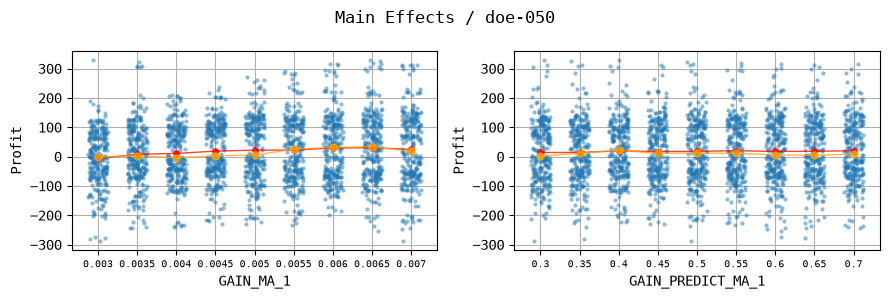

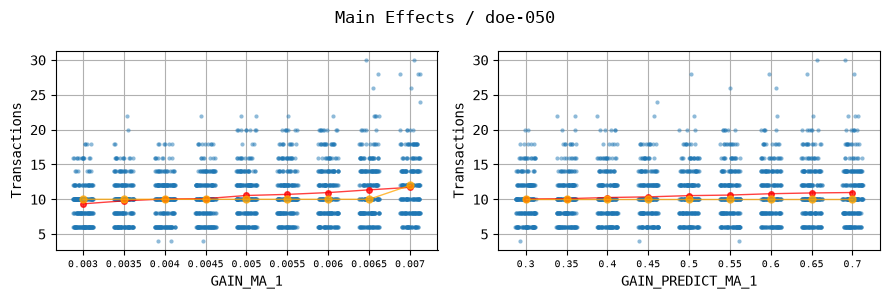

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "monospace"
# plt.rcParams["font.size"] = 11

cols_param = [
    "GAIN_MA_1",
    "GAIN_PREDICT_MA_1",
]


for name_y in ["Profit", "Transactions"]:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))

    for ax, col in zip(axes, cols_param):
        sns.stripplot(
            data=df,
            x=col,
            y=name_y,
            size=3,
            jitter=0.25,  # 横方向へのばらつき具合
            alpha=0.5,  # 重なりが見やすいよう少し透明に
            color="tab:blue",  # 散布図の色を指定
            ax=ax,
        )

        # x の各水準ごとの平均値
        mean = df.groupby(col)[name_y].mean()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(mean)),
            mean.values,
            "o-",
            color="red",
            markersize=4,
            linewidth=1,
            alpha=0.75,
            zorder=5,  # 点の裏に隠れないよう前面に描画
        )

        # x の各水準ごとのメジアン
        median = df.groupby(col)[name_y].median()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(median)),
            median.values,
            "o-",
            color="orange",
            markersize=5,
            linewidth=1,
            alpha=0.75,
            zorder=5,
        )

        ax.tick_params(axis="x", labelsize=7)
        ax.set(xlabel=col, ylabel=name_y)
        ax.grid(True)

        # ax.set_title(f"Main Effect / {name_doe}")
    fig.suptitle(f"Main Effects / {name_doe}")

    plt.tight_layout()
    pngfile = f"../../backtest/{name_doe}/main_effect_{name_y}.png"
    plt.savefig(pngfile)
    plt.show()

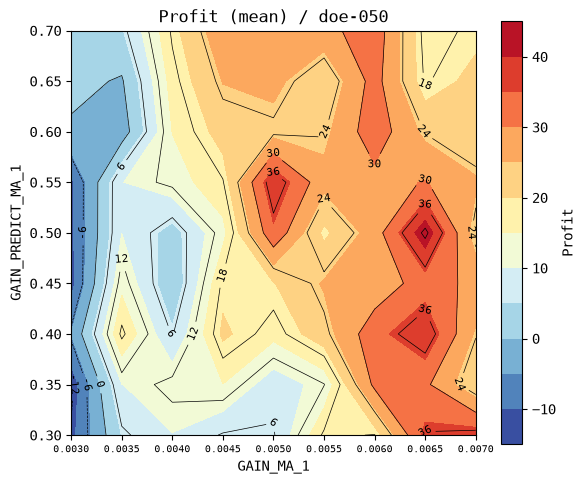

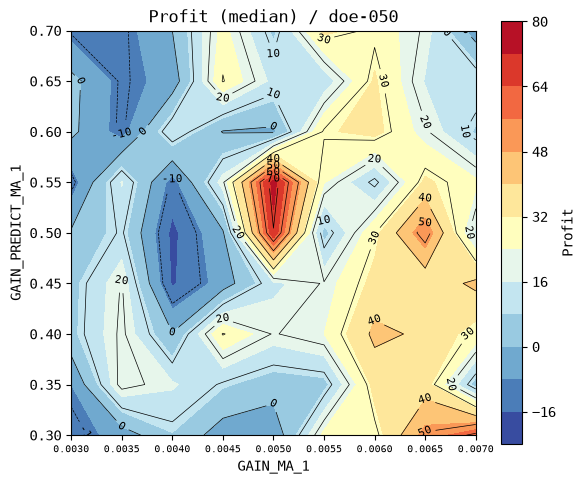

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Profit を Z 値とする格子状データを作成
# 同一パラメータの複数日分を統計処理
for stat in ["mean", "median"]:
    pivot = df.pivot_table(
        index="GAIN_PREDICT_MA_1",
        columns="GAIN_MA_1",
        values="Profit",
        aggfunc=stat,
    )

    # X, Y, Z を用意
    X, Y = np.meshgrid(
        pivot.columns,
        pivot.index,
    )
    Z = pivot.values

    # Contour Map
    fig, ax = plt.subplots(figsize=(6, 5))

    contour = ax.contourf(
        X,
        Y,
        Z,
        levels=11,
        cmap="RdYlBu_r",
    )

    # 等高線を重ねる（任意）
    lines = ax.contour(
        X,
        Y,
        Z,
        levels=10,
        colors="black",
        linewidths=0.5,
    )
    # ax.clabel(lines, inline=True, fontsize=8)
    ax.clabel(
        lines,
        inline=True,
        fontsize=8,  # フォントサイズを指定
        fmt="%.0f",  # 整数表示（任意）
    )

    # カラーバー
    fig.colorbar(contour, ax=ax, label="Profit")

    # グラフ領域を 1:1 の正方形にする
    ax.set_box_aspect(1)

    ax.tick_params(axis="x", labelsize=7)
    ax.set_xlabel("GAIN_MA_1")
    ax.set_ylabel("GAIN_PREDICT_MA_1")
    ax.set_title(f"Profit ({stat}) / {name_doe}")

    ax.grid(False)
    fig.tight_layout()

    pngfile = f"../../backtest/{name_doe}/contourmap_Profit_{stat}.png"
    plt.savefig(pngfile)
    plt.show()